In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import umap
from sklearn.cluster import KMeans
from solution_utils import build_tables, get_users_text, vectorize_topic_texts, SEED
from sklearn.metrics import homogeneity_score, completeness_score, silhouette_score, adjusted_rand_score

In [3]:
data = pd.read_json('hw1_train.jsonl', lines=True)

data

,dialog_id,language,n_user_turns,turns,labels
0,d094012177e,en,7,"[{'role': 'user', 'text': 'it’s like: 1+1=2, b...","{'task_type': 'analysis', 'reaction': 'positiv..."
1,d306fbe61fe,en,8,"[{'role': 'user', 'text': 'Can you help me tra...","{'task_type': 'information_seeking', 'reaction..."
2,dd6905952c7,en,5,"[{'role': 'user', 'text': 'ask questions about...","{'task_type': 'creation', 'reaction': 'neutral..."
3,d767a675896,en,6,"[{'role': 'user', 'text': 'Calculate each prom...","{'task_type': 'information_seeking', 'reaction..."
4,d7a6280ce8e,en,8,"[{'role': 'user', 'text': 'mass spectrometer, ...","{'task_type': 'information_seeking', 'reaction..."
...,...,...,...,...,...
9995,d745e2d0b74,en,8,"[{'role': 'user', 'text': 'which countries off...",None
9996,d2248b50e1e,en,6,"[{'role': 'user', 'text': 'Medication safety, ...",None
9997,dba01d56b0d,en,10,"[{'role': 'user', 'text': 'Your instructions a...",None
9998,d07a2ffacb8,en,5,"[{'role': 'user', 'text': 'write a story for p...",None


In [4]:
print(f'доля записей с labels {data['labels'].notna().mean()}')
data = data.drop(columns='labels')

доля записей с labels 0.3


ответы нейронки смотреть смысла нет, так как пользователь задаёт тему и ведет её, нейронка только поддакивает

In [5]:
dialogs, turn = build_tables(data.to_dict('records'))

user = dialogs.iloc[0, 2]

# for replica in user:
#     print(replica)

print (user[0])

dialogs

i


,language,n_user_turns,user_text,assistant_text,user_len,assistant_len,reaction,task_type
dialog_id,,,,,,,,
d094012177e,en,7,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined...",Introducing scientific terms from astrophysics...,8453,10492,None,None
d306fbe61fe,en,8,Can you help me train a small language model t...,Creating a small language model from scratch i...,1278,32255,None,None
dd6905952c7,en,5,ask questions about a fictional voice actor i ...,1. How did this fictional voice actor get into...,3326,11938,None,None
d767a675896,en,6,Calculate each prompt based off of data and sh...,"To calculate Species Richness, simply count th...",1115,9253,None,None
d7a6280ce8e,en,8,"mass spectrometer, the length of AC rod will i...",As an AI language model I don't have enough in...,374,7528,None,None
...,...,...,...,...,...,...,...,...
d745e2d0b74,en,8,which countries offer special programs to enco...,There are several countries that offer special...,433,11913,None,None
d2248b50e1e,en,6,"Medication safety, \n\nMedication administrati...",This documentation is important in ensuring co...,2776,5259,None,None
dba01d56b0d,en,10,Your instructions are: For the following quest...,"As an AI language model, I do not possess the ...",995,8526,None,None


In [6]:
user_text = get_users_text(data.to_dict('records'), text_type='user')

key_words_classterize = [] # будет хранить диалоги по которым будем кластеризовать
for payload in user_text['text']:
    key_words_classterize.append(payload[:2])

key_words_classterize

[['it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and into which it may result?\nIn the context of the equation “1+1=2+1+1=?,” if we want to explore the possibility of using a modulus to determine the result, we can consider different modulus values and see how they affect the equation.\n\nModulus, also known as the remainder when dividing a number by another, is often denoted by the symbol “%”. It can be used to find the remainder of a division operation.\n\nLet’s consider a few examples:\n\n1. Modulus 3:\nUsing modulus 3, we would evaluate remainders when dividing numbers by 3. Therefore:\n1 + 1 = 2 % 3 + 1 % 3 + 1 % 3\n= 2 + 1 + 1\n= 4\n\n2. Modulus 4:\nUsing modulus 4, we would evaluate remainders when dividing numbers by 4. Therefore:\n1 + 1 = 2 % 4 + 1 % 4 + 1 % 4\n= 2 + 1 + 1\n= 4\n\n3. Modulus 5:\nUsing modulus 5, we would evaluate remainders when dividing numbers by 5. Therefore:\n1 + 1 = 2 % 5 + 1 % 5 + 1 % 5\n

# мой план:
1) сделать векторизацию tf-idf 
2) подбирать кластеры kmeans++
3)  сравнивать метрики (силуэт и тд)
4) назвать темы 
5) проверть при более полном наборе диалогов
6) утвердить окончательно
7) сделать тествоую выборку (разметить темы самому)
8) обучать, сравнивать, деплоить

In [7]:
X,  tf_idfer = vectorize_topic_texts(key_words_classterize) # наши диалоги в циферках


/Users/var/Documents/projects/meow/HW/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


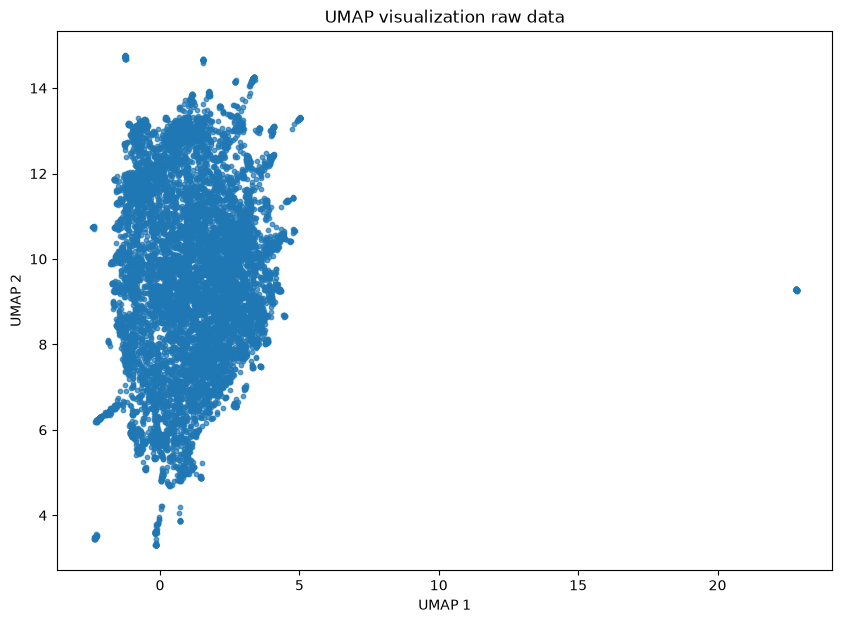

In [8]:
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric='cosine', random_state=SEED)

X_umap = reducer.fit_transform(X)

plt.figure(figsize=(10, 7))
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=10, alpha=0.7)

plt.title('UMAP visualization raw data')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.show()

In [9]:
empty_mask = np.asarray(X.getnnz(axis=1) == 0).ravel()
print("Диалогов без TF-IDF-признаков:", empty_mask.sum())

Диалогов без TF-IDF-признаков: 33


а что это за диалоги?

In [10]:
empty_indices = np.where(empty_mask)[0]

for i in empty_indices[:20]:
    print(f"Индекс: {i}")
    print(repr(key_words_classterize[i]))
    print("---")

Индекс: 353
['chào cậu', 'có']
---
Индекс: 551
['食べましたが', 'にほんご\u3000できる？']
---
Индекс: 685
['hehehehhee', 'Muwahahahahaha']
---
Индекс: 766
['你是英语翻译方面的专家。请将下面的句子翻译为英语：\n在访学期间，我经常去杨老师的实验室，与杨老师和他的学生讨论一些研究。我发现这个对我的帮助很大，访学期间我和杨老师在TSE上合作发表了一篇论文。开展了充分的合作。我回国后，依然与他着合作关系。到目前位置，我们一起合作了4-5篇期刊论文。我特别喜欢密西根州，那边环境优美、比较宁静，人们也比较友好、夏天不热、冬天也不太冷。我在那边认识了几个朋友，现在还保持着联系。', '你是英语翻译方面的专家。请将下面的句子翻译为英语：\n我曾经访问过西密歇根大学。访学开始于2018年9月，结束语2019年1月。在访学期间，我经常去杨老师的实验室，与杨老师和他的学生讨论一些研究。我发现这个对我的帮助很大，访学期间我和杨老师在TSE上合作发表了一篇论文。开展了充分的合作。我回国后，依然与他着合作关系。到目前位置，我们一起合作了4-5篇期刊论文。我特别喜欢密西根州，那边环境优美、比较宁静，人们也比较友好、夏天不热、冬天也不太冷。我在那边认识了几个朋友，现在还保持着联系。']
---
Индекс: 1605
['Translate\n\n"Вечірний ефір телеканалу Сигнал"', 'Translate\n\n"РАРИТЕТ! Рекламні заставки ТРК Київ (1995)"']
---
Индекс: 1752
['变形金刚5：最后的骑士 主要内容', '名侦探柯南：业火的向日葵 主要内容']
---
Индекс: 1760
['我昨天通过FAR DAR给fr寄了测量工具，现在想发英语邮件告诉他们，要怎么说。', '是要告诉fr']
---
Индекс: 1771
['这个实验室从一种名为蒙特卡罗采样的技术开始。我们将从一个具有几个参数的假设总体中进行采样：一种形式或形状（我们将使用正态分布的总体），具有指定的平均值和指定的标准差。\n\n让我们从制作和绘制样本开始。生成一些Python代码，从平均值为1

In [11]:
scores_silhuet = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels = kmeans.fit_predict(X)

    scores_silhuet.append((k, silhouette_score(X, cluster_labels, random_state=SEED, sample_size=None, metric='euclidean')))

score_table = pd.DataFrame(scores_silhuet, columns=["k", "silhouette_score"])
print(score_table)

     k  silhouette_score
0    3          0.002344
1    4          0.003069
2    5          0.003033
3    6          0.003646
4    7          0.004409
5    8          0.004002
6    9          0.004498
7   10          0.003561
8   11          0.004770
9   12          0.005257
10  13          0.004072
11  14          0.006211


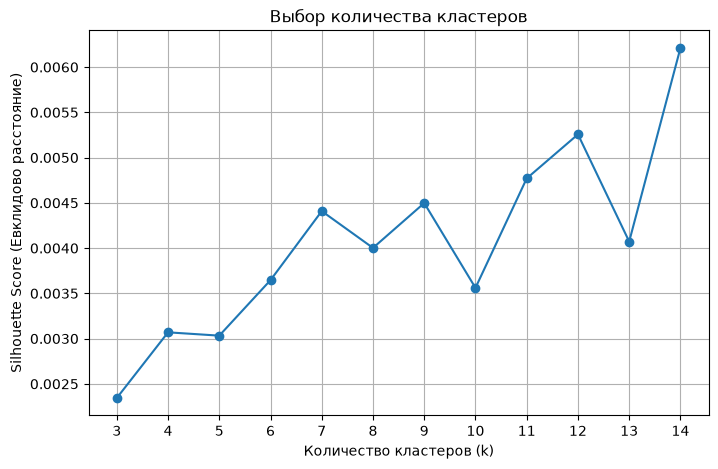

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(score_table["k"], score_table["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score (Евклидово расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table["k"])
plt.grid(True)
plt.show()

мда, силуэт порядка 0,001 это конечно сильно. можно попробовать глянуть косинусное расстояние для сравнения, а потом переходить к рассмотрению полных диалогов user и может быть даже к user+assistant

In [13]:
scores_silhuet_cos = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels_cos = kmeans.fit_predict(X)

    scores_silhuet_cos.append((k, silhouette_score(X, cluster_labels_cos, random_state=SEED, sample_size=None, metric='cosine')))

score_table_cos = pd.DataFrame(scores_silhuet_cos, columns=["k", "silhouette_score"])

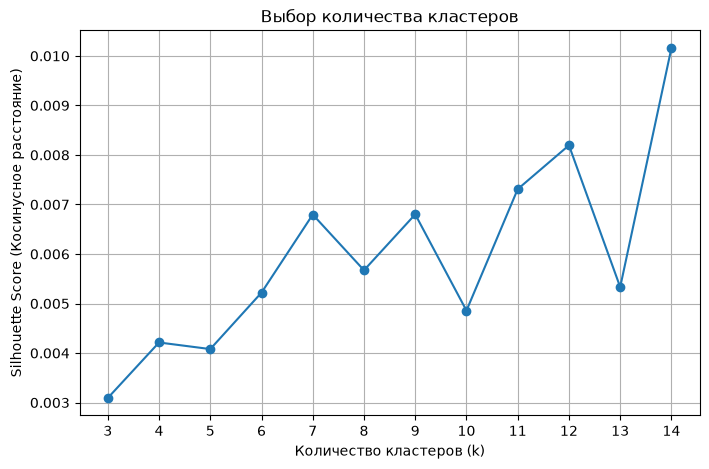

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(score_table_cos["k"], score_table_cos["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score (Косинусное расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table_cos["k"])
plt.grid(True)
plt.show()

в целом этого следовало ожидать, не, ну а вдруг) 
переходим к обучению на всех текстах user'a

In [15]:
key_words_classterize_all_user = [] # будет хранить диалоги по которым будем кластеризовать
for payload in user_text['text']:
    key_words_classterize_all_user.append(payload)

X_all_user,  tf_idfer_all_user = vectorize_topic_texts(key_words_classterize_all_user) # наши диалоги в циферках

empty_mask = np.asarray(X_all_user.getnnz(axis=1) == 0).ravel()
print("Диалогов без TF-IDF-признаков:", empty_mask.sum())

scores_silhuet_all_user = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels_all_user = kmeans.fit_predict(X)

    scores_silhuet_all_user.append((k, silhouette_score(X, cluster_labels_all_user, random_state=SEED, sample_size=None, metric='euclidean')))

score_table_all_user = pd.DataFrame(scores_silhuet_all_user, columns=["k", "silhouette_score"])
print(score_table_all_user)

Диалогов без TF-IDF-признаков: 0
     k  silhouette_score
0    3          0.002344
1    4          0.003069
2    5          0.003033
3    6          0.003646
4    7          0.004409
5    8          0.004002
6    9          0.004498
7   10          0.003561
8   11          0.004770
9   12          0.005257
10  13          0.004072
11  14          0.006211


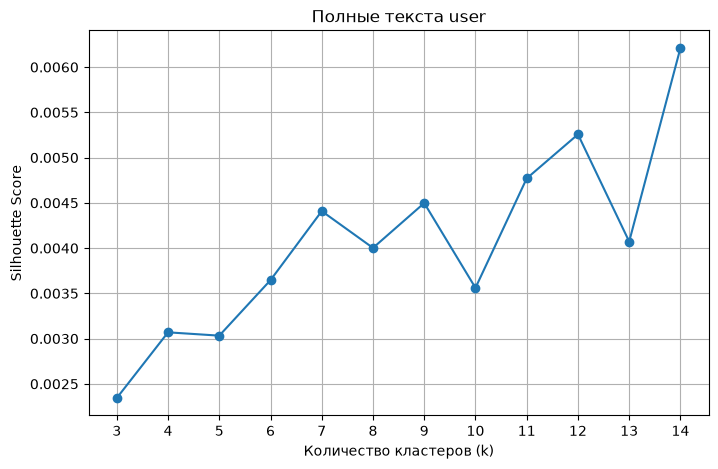

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(score_table_all_user["k"], score_table_all_user["silhouette_score"], marker="o")

plt.xlabel("Количество кластеров (k)")
plt.ylabel("Silhouette Score")
plt.xticks(score_table_all_user["k"])
plt.grid(True)
plt.title('Полные текста user')
plt.show()

попробуем еще 1 тест: урежем normalize и попробуем с менее ограниченными словами посмотреть

In [17]:
X,  tf_idfer = vectorize_topic_texts(key_words_classterize, full_normalize=False) # наши диалоги в циферках

empty_mask = np.asarray(X.getnnz(axis=1) == 0).ravel()
print("Диалогов без TF-IDF-признаков:", empty_mask.sum())

scores_silhuet = []
for k in range (3, 15):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
    cluster_labels = kmeans.fit_predict(X)

    scores_silhuet.append((k, silhouette_score(X, cluster_labels, random_state=SEED, sample_size=None, metric='euclidean')))

score_table = pd.DataFrame(scores_silhuet, columns=["k", "silhouette_score"])
print(score_table)



Диалогов без TF-IDF-признаков: 49
     k  silhouette_score
0    3          0.001648
1    4          0.002247
2    5          0.002576
3    6          0.003163
4    7          0.003202
5    8          0.003855
6    9          0.003670
7   10          0.004217
8   11          0.004380
9   12          0.004313
10  13          0.004490
11  14          0.004928


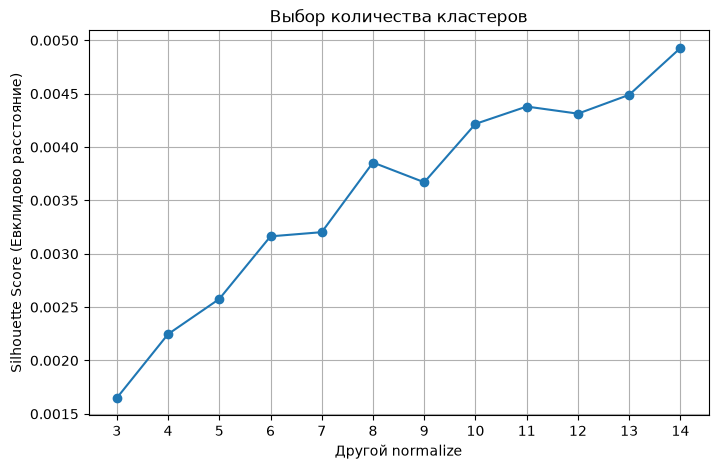

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(score_table["k"], score_table["silhouette_score"], marker="o")

plt.xlabel("Другой normalize")
plt.ylabel("Silhouette Score (Евклидово расстояние)")
plt.title("Выбор количества кластеров")
plt.xticks(score_table["k"])
plt.grid(True)
plt.show()

## Анализ диалогов

In [19]:
# 0 - chat gpt (есть в мире дураки (выбросы))
# 1 - games (иногда заигрывания 😏)
# 2 - программирование (очень хорошо распределил)
# 3 - просьбы что-то сделать? (упомянается конкретное действие)
# 4 - просьба что-то расчитать, прикинуть (что-то люто непонятное)
# 5 - что-то для школьников/простое (возможно выбросы)
# 6 - Упомянаются какие-то люди
# 7 - хрень не на русском (обычно что-то перевести или реально запросы)

In [20]:
kmeans = KMeans(n_clusters=14, init='k-means++', n_init=10, max_iter=300, random_state=SEED)
cluster_labels = kmeans.fit_predict(X)

In [21]:
dialog_table_to_analyze = []
for theme_idx in range(14):
    indexes = cluster_labels == theme_idx
    themed_dialog = data[indexes]

    print(f'Кластер {theme_idx}, количество диалогов: {len(themed_dialog)}')

    n_samples = min(15, len(themed_dialog))

    if n_samples > 0:
        selected_indices = np.random.choice(
            len(themed_dialog),
            size=n_samples,
            replace=False
        )
        get_dialog = themed_dialog.iloc[selected_indices].values.tolist()
    else:
        get_dialog = []

    dialog_table_to_analyze.append((theme_idx, get_dialog))

dialog_table_to_analyze = pd.DataFrame(dialog_table_to_analyze, columns=['theme', 'dialog'])

Кластер 0, количество диалогов: 82
Кластер 1, количество диалогов: 723
Кластер 2, количество диалогов: 794
Кластер 3, количество диалогов: 457
Кластер 4, количество диалогов: 837
Кластер 5, количество диалогов: 540
Кластер 6, количество диалогов: 3660
Кластер 7, количество диалогов: 138
Кластер 8, количество диалогов: 140
Кластер 9, количество диалогов: 549
Кластер 10, количество диалогов: 180
Кластер 11, количество диалогов: 1127
Кластер 12, количество диалогов: 25
Кластер 13, количество диалогов: 748


In [22]:
dialog_table_to_analyze['dialog'][13]

[['dace6584e09',
  'en',
  6,
  [{'role': 'user',
    'text': 'write an email to someone about taking a certification test and if they could help with the cost of it'},
   {'role': 'assistant',
    'text': 'Subject: Request for Financial Assistance for Certification Test\n\nDear [Recipient],\n\nI hope this email finds you well. I am writing to discuss the possibility of receiving financial assistance for an upcoming certification test that I am planning to take. \n\nAs you may know, obtaining this certification is crucial for my career advancement and personal growth. However, the cost of the exam and study materials is quite significant, and I am currently facing financial constraints that make it difficult for me to cover the expenses on my own.\n\nI truly believe that this certification will not only benefit me professionally but also contribute to my overall skill development and expertise in the field. Therefore, I am reaching out to you to inquire if you would be willing to assis

для кластера 4 имеем явно 1 человека который фанфики пишет. сохраним id его диалогов

In [23]:
funfic_id = data[cluster_labels == 4]['dialog_id'].tolist()
funfic_id

['d094012177e',
 'd37ac19fd7a',
 'dd54ca8089d',
 'd4c5e547fb1',
 'd913b9435ee',
 'd237c114832',
 'd7a4a7893a6',
 'd1666f4cf5e',
 'd06bfb34ef5',
 'd6d4150432e',
 'ddd3ec665a0',
 'd394ee15433',
 'de4e0bc2124',
 'd4157de1bfd',
 'df01ba1b682',
 'd42d15b8cad',
 'dbc4865f03c',
 'd768840845c',
 'dd54dd06765',
 'db80fc930f3',
 'd800498312b',
 'db3a30e7e53',
 'd192fc817e9',
 'dae044ad0a1',
 'd0ea704fba7',
 'df4c5377709',
 'd78fabefc1a',
 'd7b12128f62',
 'd08d3c7595e',
 'd81181669f1',
 'd4c93b70d0b',
 'de7c5c04d1a',
 'dad1dab8c79',
 'dfbc6fbddad',
 'd1d5df862a1',
 'd10579146ab',
 'dc1455576fb',
 'da4e88abc43',
 'd65f0ded1b6',
 'd8bd761f551',
 'd099acf8755',
 'd612485af2b',
 'd47bea47a52',
 'd990d41f41e',
 'dd1064c5e12',
 'de4c08ef3fc',
 'd4697a8a24d',
 'd5eb7f7f879',
 'dcd4b059e7d',
 'd550a248a93',
 'd4ed519f4ed',
 'db2f4cb39dd',
 'd1ce899cee4',
 'db1d62098d6',
 'd67f0bd3317',
 'dd5f2b74d82',
 'dc75b05aea5',
 'dc3369173bd',
 'dd1a5aeab82',
 'd41e2761977',
 'dabd7ec107c',
 'd8a15c22412',
 'd1ea2b

In [24]:
dist = kmeans.transform(X)               # (n_dialogs, 8)
labels = kmeans.labels_                  # или ваш cluster_labels

own_dist = dist[np.arange(X.shape[0]), labels]   # расстояние до своего центроида

# margin: насколько диалог ближе к своему центру, чем ко второму по близости
sorted_dist = np.sort(dist, axis=1)
margin = sorted_dist[:, 1] - sorted_dist[:, 0]   # маленький = на границе двух кластеров

N = 10
rows = []
for k in range(14):
    idx = np.where(labels == k)[0]

    center_idx = idx[np.argsort(own_dist[idx])[:N]]          # самые типичные
    far_idx    = idx[np.argsort(-own_dist[idx])[:N]]         # самые далёкие от центра
    border_idx = idx[np.argsort(margin[idx])[:N]]            # на стыке с другим кластером
    random_idx = np.random.choice(idx, min(N, len(idx)), replace=False)

    # к какому кластеру "тянет" пограничные диалоги
    neighbor = np.argsort(dist[border_idx], axis=1)[:, 1]

    for kind, ids in [('center', center_idx), ('far', far_idx),
                      ('border', border_idx), ('random', random_idx)]:
        for i in ids:
            rows.append({
                'theme': k,
                'kind': kind,
                'second_cluster': np.argsort(dist[i])[1],
                'dist': own_dist[i],
                'dialog': data.iloc[i],
            })

df = pd.DataFrame(rows)
# print(df[(df.theme == 0) & (df.kind == 'center')]['dialog'].tolist())
df

,theme,kind,second_cluster,dist,dialog
0,0,center,6,0.662258,dialog_id ...
1,0,center,6,0.662258,dialog_id ...
2,0,center,6,0.662258,dialog_id ...
3,0,center,6,0.721660,dialog_id ...
4,0,center,10,0.806173,dialog_id ...
...,...,...,...,...,...
555,13,random,9,0.992274,dialog_id ...
556,13,random,6,0.993839,dialog_id ...
557,13,random,6,0.974257,dialog_id ...
558,13,random,6,0.991299,dialog_id ...


In [25]:
df[(df['theme'] == 1) & (df['kind'] == 'center')]['dialog'].tolist()[7]['turns']

[{'role': 'user',
  'text': 'این متن زیر را به بهترین شیوه به فارسی ترجمه کن\n\nThis is the voice not of the third-person narrator but of Rosa Coldfield, who\nbecomes the principal narrator of the story. The impersonal narrator is equally\nvoluble, with phrases like “augmenting and defunctive twilight” and “retroactive\novercoming of primary inertia” arranged in a tumble of clauses and phrases,\nalthough he is less emotional. Rosa, in addition to being unthinkingly racist in\nthe way of her time and place, as in the “apelike body” description, is living\nthrough events from many years earlier as if they just happened, and their\nvividness gives her narration a slightly hysterical tone. The verbs—“flaunt,”\n“fling,” “retaliate,” “cursing,” “panting,” “laughing”—are active and sharp, the\nnouns frequently long and Latinate—“implacability,” “imperviousness”—but\nalso strong and clear, as in “stevedores,” “deckhands,” and “honky-tonks.” And\nthe punctuation! What punctuation! There’s a rea

# Итоговый список тем:
1) IT (программирование) (coding)
2) вопросы про ИИ 
3) перевод на другие языки (работа с языками)
4) работа с текстом
5) объяснение/разъяснение общих вопросов (questioning/explanation)
6) нахождение информации
7) математика, расчеты, решение задач
8) ПРОЧЕЕ/ВСЯКОЕ